# Ten-qubit PQDQN: Pauli propagation versus Lightning

A reproducible **simulator microbenchmark**, using ten qubits, four YZ/reuploading layers and CNOT rings including the final layer. Ten shared single-Z features feed a biased, two-output classical head. All backends use matched parameters and inputs. We compare `lightning.qubit`/adjoint with QASP's `lightning.pp`/Torch autograd at Pauli-weight cutoffs `k=2,3`, with coefficient/top-M pruning disabled.

This notebook loads the measured five-seed results. It does not rerun the CartPole learning experiment or claim that faster approximate gradients imply faster learning.

In [1]:
from pathlib import Path
import sys
import json
import torch
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd() if (Path.cwd() / "qasp").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "examples"))
from pqdqn_pauli_propagation_benchmark import OUTPUT, make_model, main
from pqdqn_paper_figures import save_circuit_drawing

torch.set_num_threads(1)
manifest = json.loads((OUTPUT / "manifest.json").read_text())
assert "completed_utc" in manifest
print("Seeds:", manifest["seeds"], "Batches:", manifest["batches"])
print("Parameters:", manifest["parameter_count"], "Precision:", manifest["dtype"])

Seeds: [7, 8, 9, 10, 11] Batches: [1, 8]
Parameters: 142 Precision: float64


## Differentiable ten-qubit example and paper circuit

`make_model` constructs PQDQN using the dictionary in the companion script. Change `pp_k2` to `pp_k3` or `lightning_qubit` for the other measured settings. The quantum circuit and classical head are identical for all three, so the figure applies to each backend. The saved readout JSON defines the ten separate expectations and biased head. The expanded circuit is also exported.

Q values: [[-0.28018182  0.11202285]]
Finite gradients for all trainable parameters.


/private/tmp/qasp-slurm-venv/lib/python3.13/site-packages/pennylane/operation.py:1982: PennyLaneDeprecationWarning: The 'id' argument is deprecated and will be removed in v0.46.
  super().__init__(*params, wires=wires, id=id)


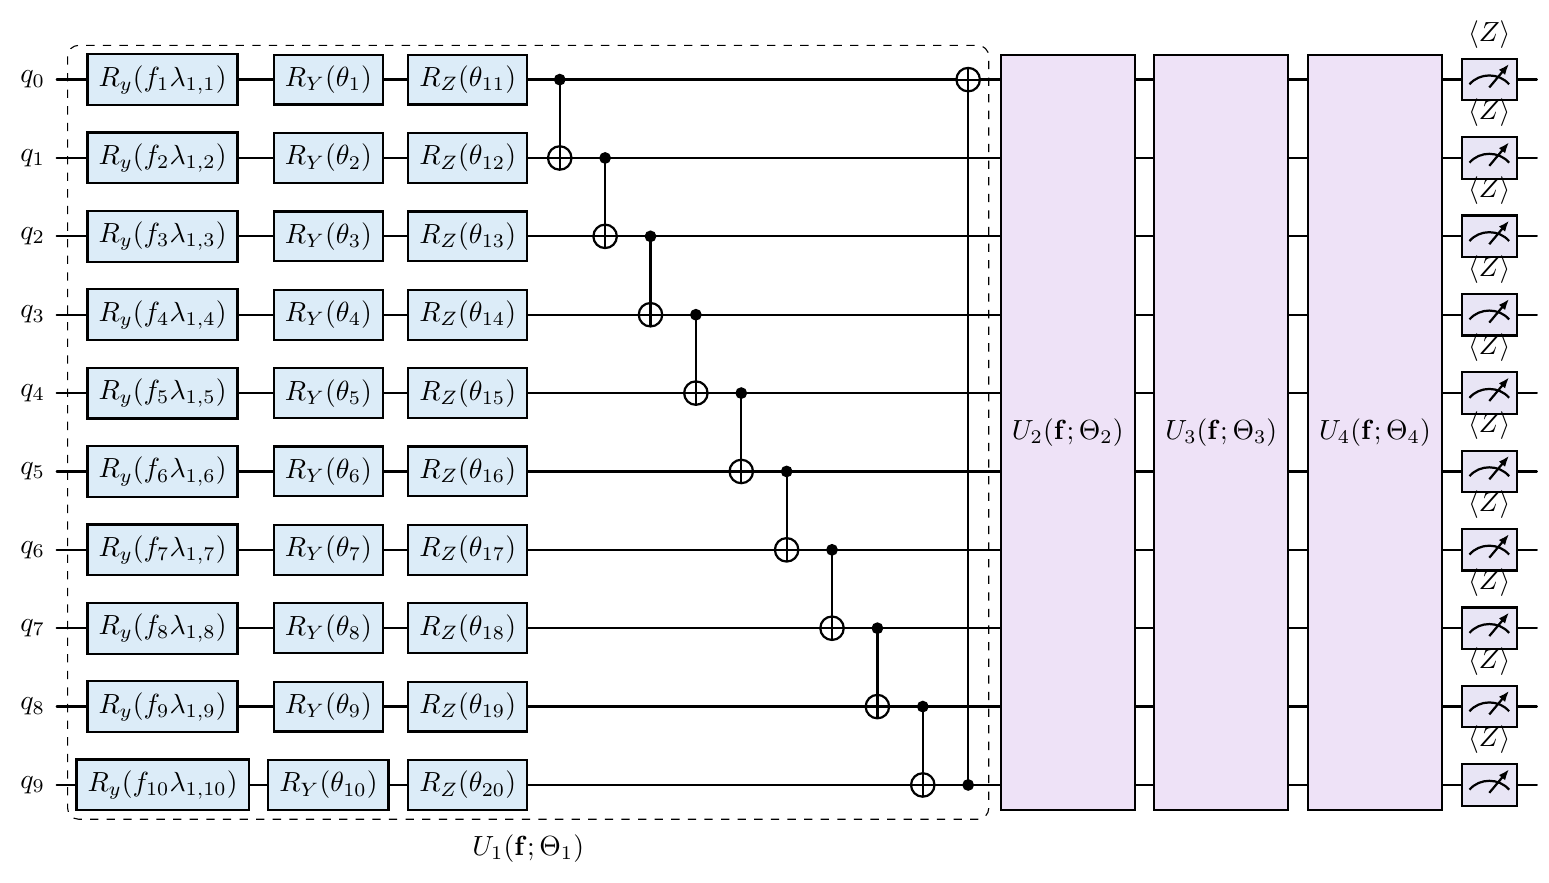

In [2]:
model = make_model("pp_k2")
saved = torch.load(OUTPUT / "seed_7.pt", weights_only=True)
model.load_state_dict(saved["state_dict"])
x = saved["inputs"][:1]
q = model(x)
q.square().mean().backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
print("Q values:", q.detach().numpy())
print("Finite gradients for all trainable parameters.")
drawings = save_circuit_drawing(model, OUTPUT / "drawings")
display(Image(filename=drawings["preview"]))

## Measured runtime

Two warmups and seven timed repeats per seed, backend, workload and batch size. Backend order is shuffled within each repeat. The table reports the mean and **sample standard deviation of five within-seed median times**, in milliseconds per whole batch. Inference uses `no_grad`; forward/backward includes zeroing gradients, a selected-action mean Huber loss and backward. No optimizer, replay sampling, target-network or environment work is timed.

,batch_size,backend,workload,mean,std,min,max
0,1,lightning_qubit,forward_backward,28.591933,5.453168,23.600958,36.754000
1,1,lightning_qubit,inference,26.902275,7.435376,20.903792,38.281084
2,1,pp_k2,forward_backward,16.693058,1.867236,14.370459,18.944875
3,1,pp_k2,inference,13.889700,4.273844,10.197791,20.067917
4,1,pp_k3,forward_backward,48.243709,10.119422,40.897792,64.961792
5,1,pp_k3,inference,30.865875,8.146049,25.508584,45.215541
6,8,lightning_qubit,forward_backward,198.016683,9.003565,188.941167,211.289625
7,8,lightning_qubit,inference,190.473433,27.708263,163.657250,232.278875
8,8,pp_k2,forward_backward,110.288225,8.160799,102.060208,122.540708
9,8,pp_k2,inference,83.182391,7.530063,75.986917,95.531458


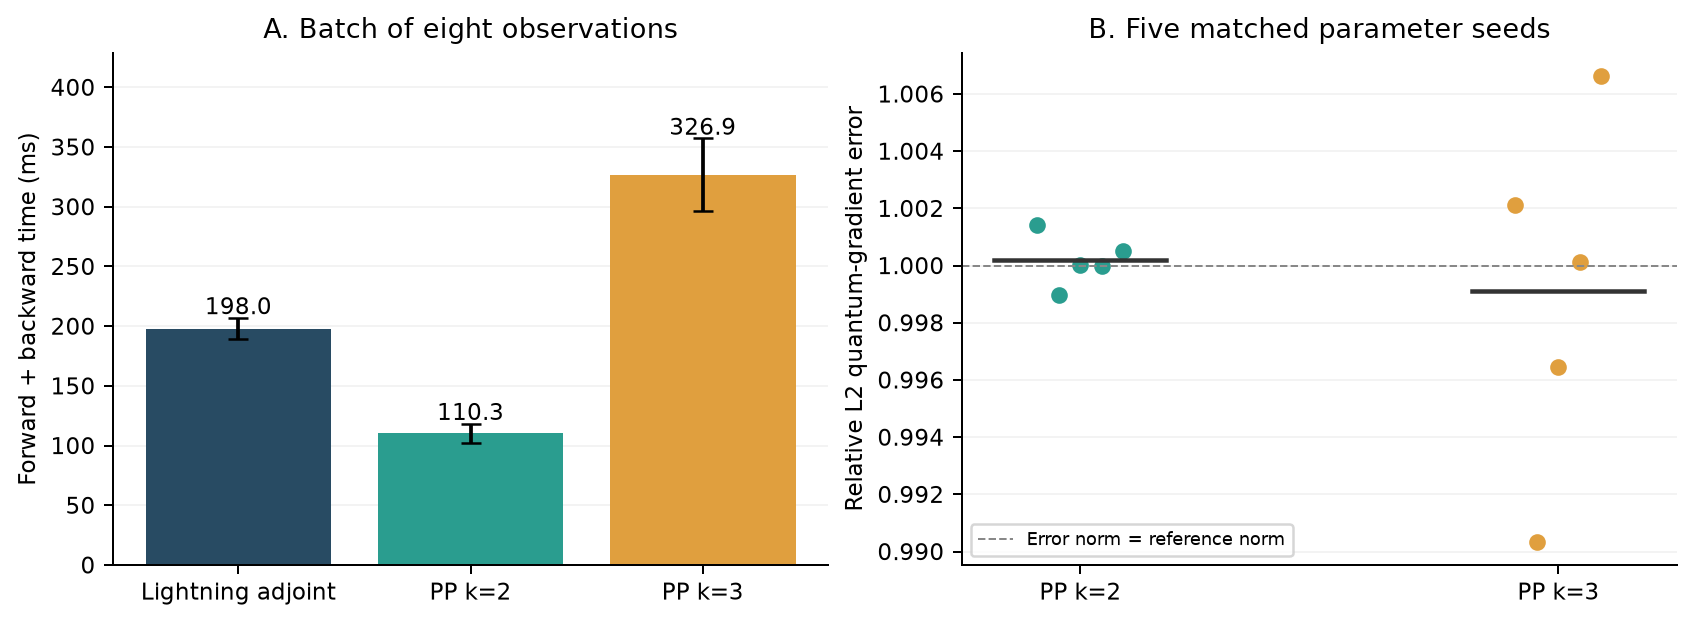

In [3]:
timings = pd.read_csv(OUTPUT / "timing_summary.csv")
display(timings)
display(Image(filename=str(OUTPUT / "timing_accuracy.png")))

## Approximation error and correctness

Metrics below are averaged across the five matched model seeds. Quantum-gradient relative L2 error includes variational rotation and input-scaling parameters, excluding the head. Values near one indicate an error norm comparable to the exact gradient norm. Small absolute Q errors can conceal much larger quantum-feature errors because the head and bias are shared.

Lightning values/gradients are independently checked against default.qubit/backprop. Directional finite differences check that PP differentiates its own truncated function correctly. Neither check makes the truncated function equal to the exact circuit.

In [4]:
accuracy = pd.read_csv(OUTPUT / "accuracy_summary.csv")
display(accuracy)
checks = json.loads((OUTPUT / "verification.json").read_text())
assert all(check["passed"] for check in checks)
display(pd.DataFrame(checks))
print("Report:", ROOT / "output/pdf/pqdqn_10qubit_backend_report.pdf")

,batch_size,backend,feature_rmse,q_rmse,feature_relative_l2,quantum_gradient_relative_l2,quantum_gradient_cosine
0,1,lightning_qubit,0.000000,0.000000,0.000000,0.000000,1.000000
1,1,pp_k2,0.030395,0.020541,0.999995,0.998658,-0.020395
2,1,pp_k3,0.030364,0.020160,0.999462,1.035473,-0.001214
3,8,lightning_qubit,0.000000,0.000000,0.000000,0.000000,1.000000
4,8,pp_k2,0.031643,0.017635,0.998393,1.000180,-0.015135
5,8,pp_k3,0.031614,0.017546,0.997296,0.999127,0.037212


,test,passed,seed,batch,max_gradient_error,backend,autodiff,finite_difference,absolute_error
0,lightning_adjoint_vs_default_backprop,True,7.0,8.0,2.519603e-10,NaN,NaN,NaN,NaN
1,truncated_gradient_directional_finite_difference,True,NaN,NaN,NaN,pp_k2,-0.001317,-0.001317,5.532483e-12
2,truncated_gradient_directional_finite_difference,True,NaN,NaN,NaN,pp_k3,-0.001112,-0.001112,3.857813e-13


Report: /Users/andresequeira/Desktop/QASP/output/pdf/pqdqn_10qubit_backend_report.pdf


## Reproduce

The companion script is `examples/pqdqn_pauli_propagation_benchmark.py`. From the repository root, run it with `PYTHONPATH=.` and `OMP_NUM_THREADS=OPENBLAS_NUM_THREADS=MKL_NUM_THREADS=1`, and pass `--output` with a **new** directory. It refuses to overwrite existing data. Use a fresh process so the Torch inter-op thread setting can be applied before work starts.

The results directory preserves raw timings/errors, five initial model states and inputs, setup times, configuration, package versions and source hashes. The separate rendering script rebuilds the figures and PDF from these saved results.

**Interpretation:** for this workload, k=2 is faster and k=3 is slower than Lightning. Both low cutoffs have large quantum-gradient errors. These initialization-point timings do not establish comparable learning performance, general scaling, or an accuracy-preserving speedup. The five parameter seeds are measured in one local machine session.